# Exploratory Data Analysis

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
DATA_CANDIDATES = [Path("data/ozone.csv"), Path("../data/ozone.csv")]
DATA = next((path for path in DATA_CANDIDATES if path.exists()), None)
if DATA is None:
    raise FileNotFoundError("Could not find data/ozone.csv.")

df = pd.read_csv(DATA)
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")
target = "Class"
id_cols = ["Dataset", "Date"]
feature_cols = [c for c in df.columns if c not in id_cols + [target]]
print("Shape:", df.shape)
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Non-numeric feature columns:", df[feature_cols].select_dtypes(exclude="number").columns.tolist())

Shape: (5070, 75)
Date range: 1998-01-01 to 2004-12-12
Non-numeric feature columns: []


## 1. Dataset composition and target balance

In [5]:
print("Rows by dataset:")
print(df["Dataset"].value_counts())
print("\nTarget counts:")
print(df[target].value_counts())
print("\nTarget proportions by dataset:")
print(pd.crosstab(df["Dataset"], df[target], normalize="index").round(3))

Rows by dataset:
Dataset
1hr    2536
8hr    2534
Name: count, dtype: int64

Target counts:
Class
0    4837
1     233
Name: count, dtype: int64

Target proportions by dataset:
Class        0      1
Dataset              
1hr      0.971  0.029
8hr      0.937  0.063


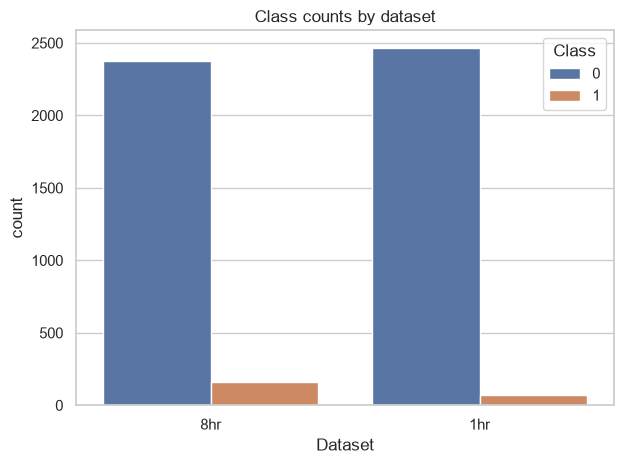

In [6]:
sns.countplot(data=df, x="Dataset", hue=target)
plt.title("Class counts by dataset")
plt.tight_layout()

The positive class is uncommon, so accuracy should not be the only evaluation metric. Class proportions also differ between the two dataset versions; this should be considered when splitting the data.

## 2. Missing values

In [7]:
missing = df[feature_cols].isna().sum().sort_values(ascending=False)
missing_table = pd.DataFrame({"missing_count": missing, "missing_percent": 100 * missing / len(df)})
print("Percent of rows with at least one missing feature:", round(df[feature_cols].isna().any(axis=1).mean() * 100, 2))
display(missing_table[missing_table["missing_count"] > 0].round(2))

Percent of rows with at least one missing feature: 27.12


,missing_count,missing_percent
WSR22,600,11.83
WSR0,598,11.79
WSR23,594,11.72
WSR2,588,11.60
WSR20,588,11.60
...,...,...
HT70,200,3.94
T85,198,3.91
SLP,190,3.75
HT85,190,3.75


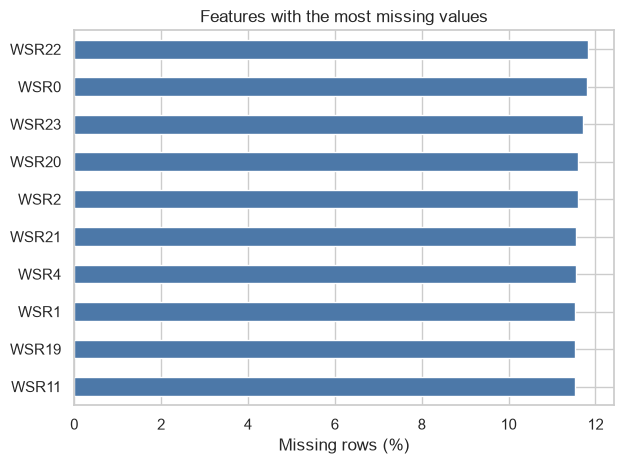

In [8]:
missing_table["missing_percent"].head(10).sort_values().plot.barh(color="#4c78a8")
plt.title("Features with the most missing values")
plt.xlabel("Missing rows (%)")
plt.tight_layout()

Missing values are concentrated in a small group of wind-speed features. Imputation should be performed inside the modeling pipeline so that information from the test set is not used.

## 3. Features associated with the target

In [9]:
correlations = df[feature_cols + [target]].corr(numeric_only=True)[target].drop(target).sort_values()
print("Most negative associations:")
display(correlations.head(5).round(3).to_frame("correlation"))
print("Most positive associations:")
display(correlations.tail(5).sort_values(ascending=False).round(3).to_frame("correlation"))

Most negative associations:


,correlation
WSR12,-0.206
WSR10,-0.203
WSR11,-0.203
WSR13,-0.185
WSR9,-0.183


Most positive associations:


,correlation
T15,0.221
T16,0.219
T14,0.217
T17,0.213
T13,0.210


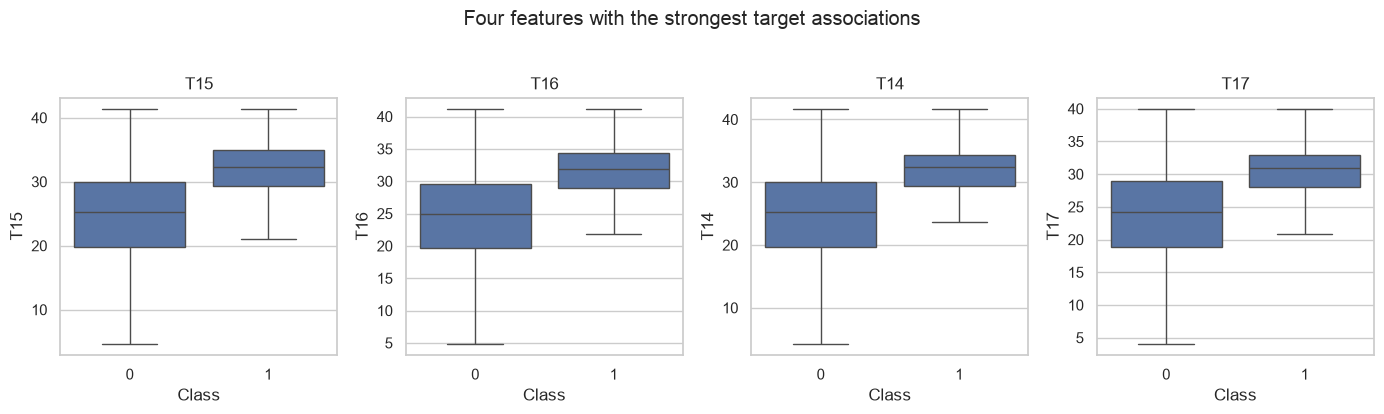

In [10]:
top_features = correlations.abs().sort_values(ascending=False).head(4).index
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, feature in zip(axes, top_features):
    sns.boxplot(data=df, x=target, y=feature, showfliers=False, ax=ax)
    ax.set_title(feature)
plt.suptitle("Four features with the strongest target associations", y=1.03)
plt.tight_layout()

The strongest associations are mainly temperature and wind-speed variables. These are useful directions for modeling, but correlation does not establish causation. The hourly measurements are related, so regularization or feature selection may be useful.

## Summary

- The target is imbalanced and should be evaluated with more than accuracy.
- Missing values need to be handled during model preprocessing.
- Temperature and wind-speed variables show the clearest univariate relationships with the target.
- The two dataset versions should be tracked separately when evaluating model performance.